# 04 · June - Augst 
route glow map: electric + conventional bikes

Uses **modelled** GraphHopper routes, not GPS tracks. Run the public data/routing steps in README first. Cyan = electric; magenta = conventional. Overlap makes hues blend; brightness and relative dominance should not be interpreted as exposure or street-level bicycle counts. The script routes the most frequent OD pairs by default, so maps represent a **subset** until routing is complete.

In [6]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path(
    "/scratch/project_2010417/paper3/toronto-bikeshare-viz"
)

sys.path.insert(0, str(ROOT / "scripts"))

from viz_routes import load, aggregate, plot, BG, COLORS

OUT = ROOT / "outputs/maps"
OUT.mkdir(parents=True, exist_ok=True)

# Load all three summer months
june, routes = load(2026, 6)
july, _ = load(2026, 7)
august, _ = load(2026, 8)

# Combine the trip records
trips = pd.concat(
    [june, july, august],
    ignore_index=True
)

# Aggregate the entire summer
monthly = aggregate(trips, routes)

print("Summer 2026")
print(f"Recognised bike-type trips: {len(trips):,}")
print(f"Routed OD–bike-type combinations: {len(monthly):,}")
print(f"Mapped trips: {monthly.n.sum():,}")
print(f"Coverage: {monthly.n.sum() / len(trips):.2%}")

Summer 2026
Recognised bike-type trips: 3,509,478
Routed OD–bike-type combinations: 481,584
Mapped trips: 3,435,686
Coverage: 97.90%


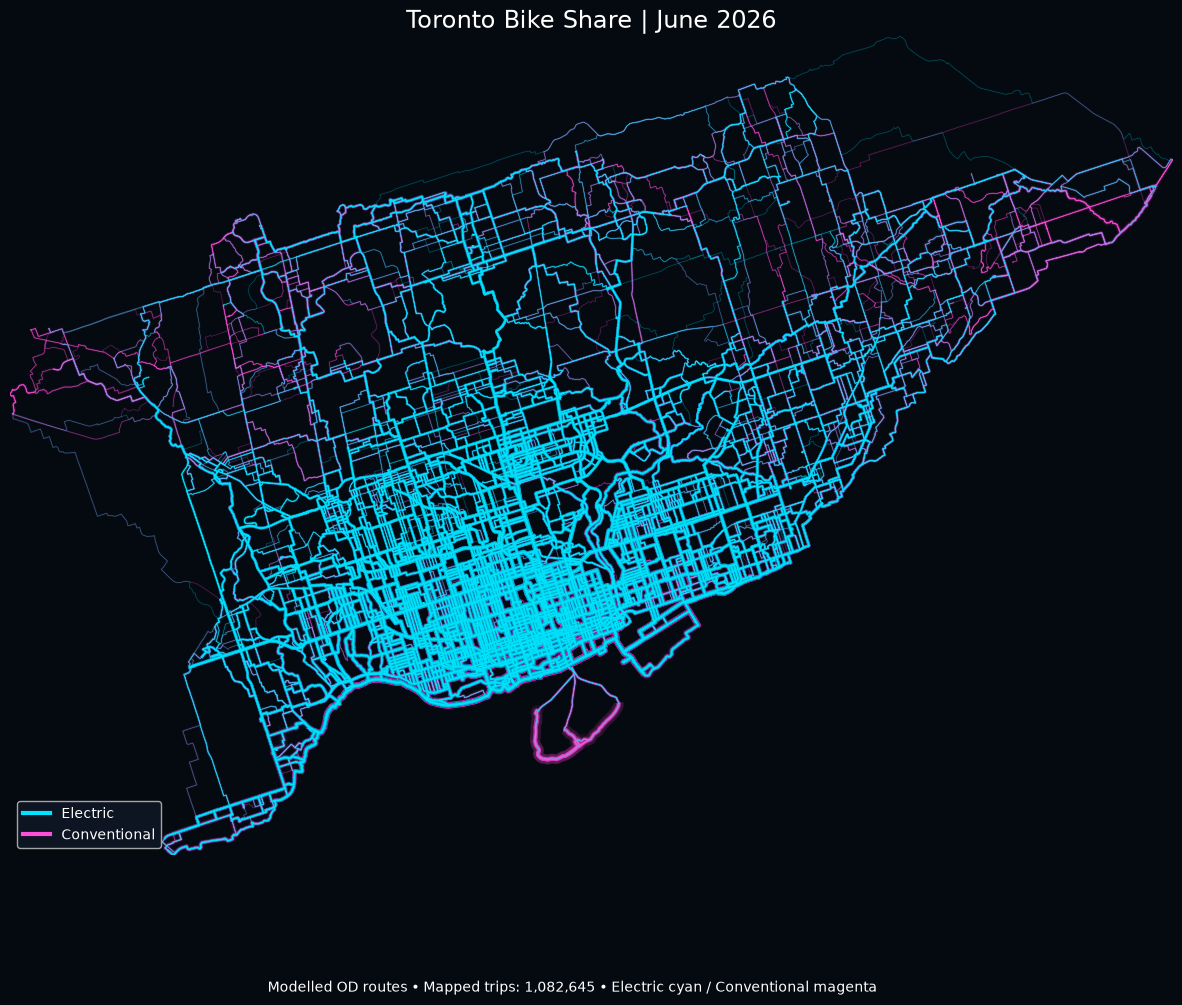

In [5]:
fig, ax = plt.subplots(figsize=(15,12),facecolor=BG)
plot(ax, monthly, routes.total_bounds, monthly.n.max(), 'Toronto Bike Share | June 2026')
ax.legend(handles=[Line2D([0],[0],color=COLORS[k],lw=3,label=k) for k in ['Electric','Conventional']],facecolor='#101827',labelcolor='white',loc='lower left')
fig.text(.5,.04,f'Modelled OD routes • Mapped trips: {monthly.n.sum():,} • Electric cyan / Conventional magenta',ha='center',color='white')
fig.savefig(OUT/'june_bike_type_overlay.png',dpi=190,facecolor=fig.get_facecolor(),bbox_inches='tight')
plt.show()